# Apple Inc. (AAPL) | Advanced Statistical Analysis

This mini-project uses the [historical archive supplied by Developers Institute](https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/blob/main/Week%203/W3D4%20-%20Mini%20Project/Apple%20Stock%20Prices%20From%201981%20to%202023.zip). Keep the supplied ZIP in the notebook folder. Install the dependencies with `python -m pip install numpy pandas scipy matplotlib` in your Jupyter environment and run all cells. Prices use the historical scale provided by the source.

# 1. Load and explore the data

Audit source types and missing values, then prepare a chronological series. Day gaps include weekends and exchange holidays. Each return is calculated between consecutive available observations.

In [1]:
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from scipy import signal, stats

# 1. Read the stock CSV directly from the course archive.
with ZipFile("apple_stock_prices.zip") as archive:
    csv_files = [name for name in archive.namelist()
                 if name.lower().endswith(".csv") and "__MACOSX" not in name]
    with archive.open(csv_files[0]) as csv_file:
        raw = pd.read_csv(csv_file)

# 2. Inspect the file before converting dates and numeric fields.
raw.columns = raw.columns.str.strip().str.lower().str.replace(" ", "_")
columns = ["open", "high", "low", "close", "adj_close", "volume"]
print("Source types and missing counts:")
print(pd.DataFrame({"type": raw.dtypes, "missing": raw.isna().sum()}).to_string())
stock = raw[["date", *columns]].drop_duplicates().copy()
stock["date"] = pd.to_datetime(stock["date"], format="%d/%m/%Y", errors="coerce")
stock[columns] = stock[columns].apply(pd.to_numeric, errors="coerce")

# 3. Parse day/month/year dates and keep complete, consistent OHLCV rows.
valid_prices = stock[columns[:-1]].gt(0).all(axis=1)
valid_range = stock["high"].ge(stock[["open", "close"]].max(axis=1))
valid_range &= stock["low"].le(stock[["open", "close"]].min(axis=1))
valid_rows = stock["date"].notna() & valid_prices & valid_range & stock["volume"].ge(0)
stock = stock.loc[valid_rows].set_index("date").sort_index()
assert stock.index.is_unique, "Conflicting rows share a trading date."
dates = stock.index
day_gaps = dates.to_series().diff().dt.days.value_counts().sort_index()
print(f"\nKept {len(stock):,} of {len(raw):,} rows: {dates[0]:%Y-%m-%d} through {dates[-1]:%Y-%m-%d}.")
print("Calendar days between observations:\n", day_gaps.to_string())
print(f"Weekend observations: {sum(dates.dayofweek >= 5)}")
print(f"First/last close: ${stock['close'].iloc[0]:.4f} / ${stock['close'].iloc[-1]:.2f}")


Source types and missing counts:
              type  missing
date        object        0
open       float64        0
high       float64        0
low        float64        0
close      float64        0
adj_close  float64        0
volume       int64        0

Kept 10,608 of 10,608 rows: 1981-01-02 through 2023-01-27.
Calendar days between observations:
 date
1.0    8317
2.0      95
3.0    1927
4.0     265
5.0       2
7.0       1
Weekend observations: 0
First/last close: $0.1540 / $145.93


# 2. Visualize prices, volume and candlesticks

The long view uses a logarithmic price axis to keep early prices readable. The candlestick view shows the last 60 sessions on a linear scale. Each wick spans the low to the high. Each body spans the open to the close.

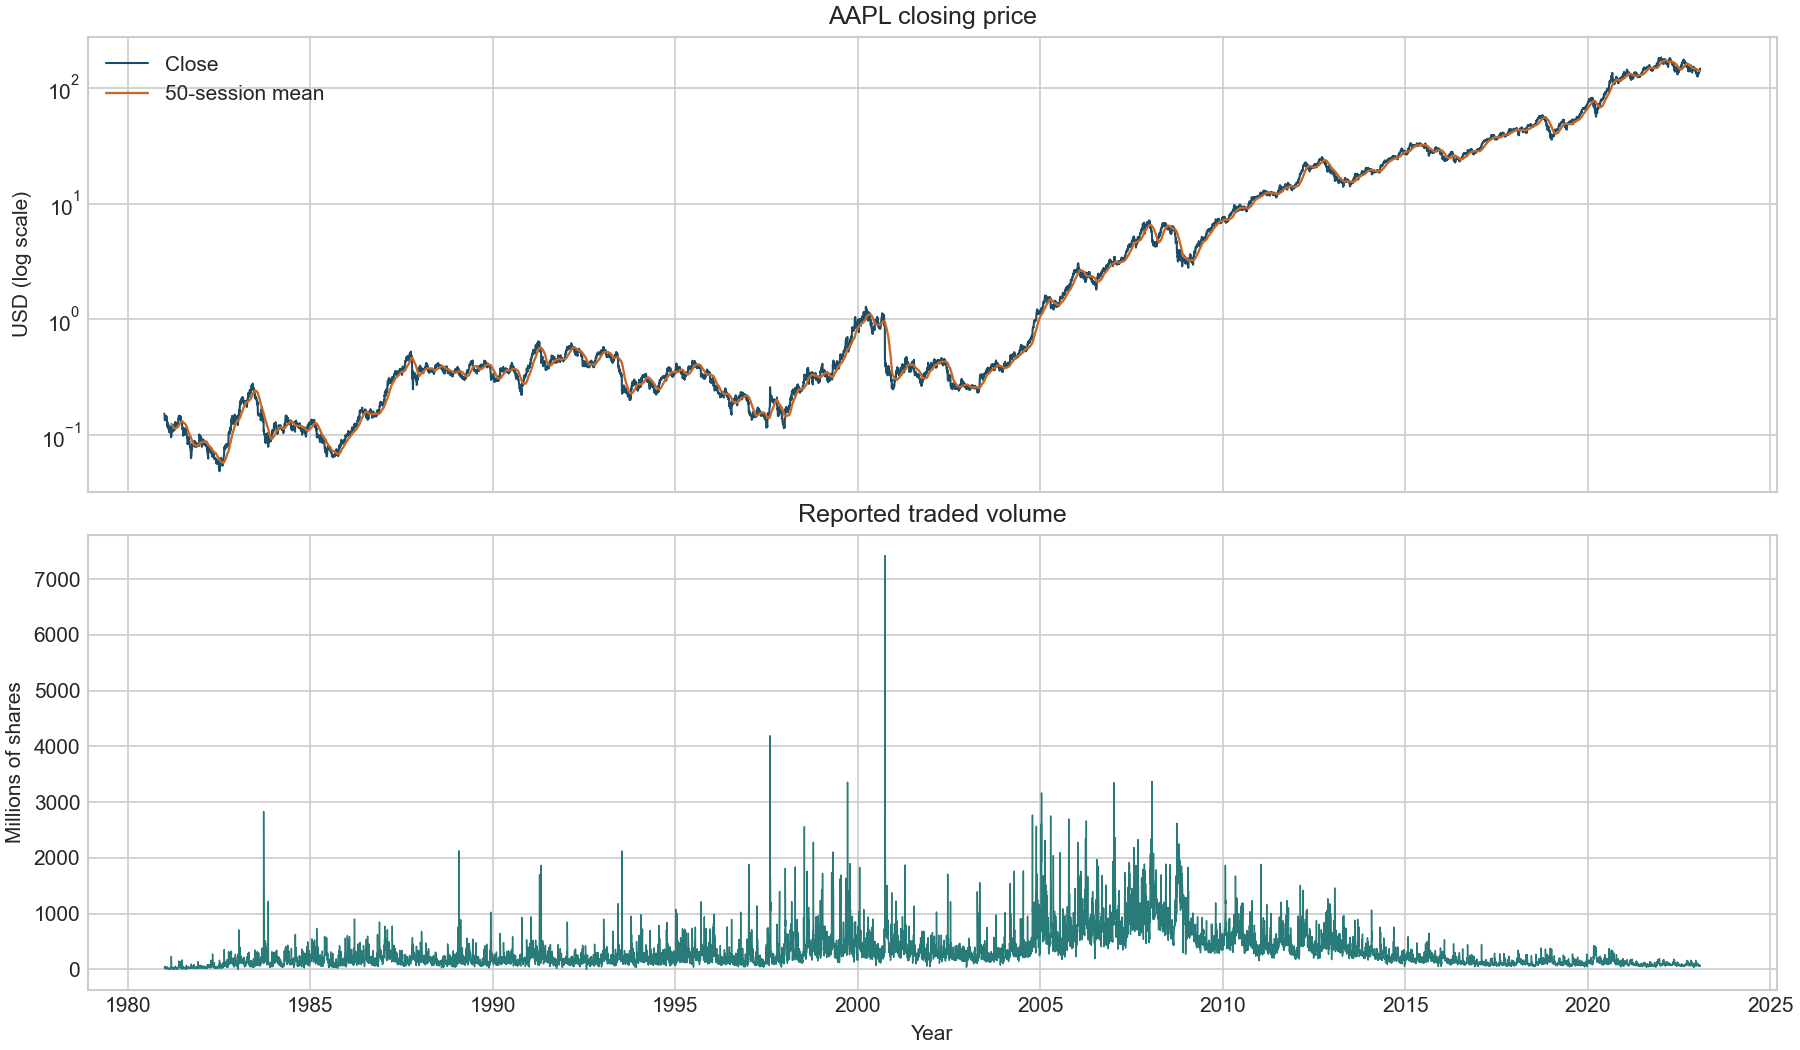

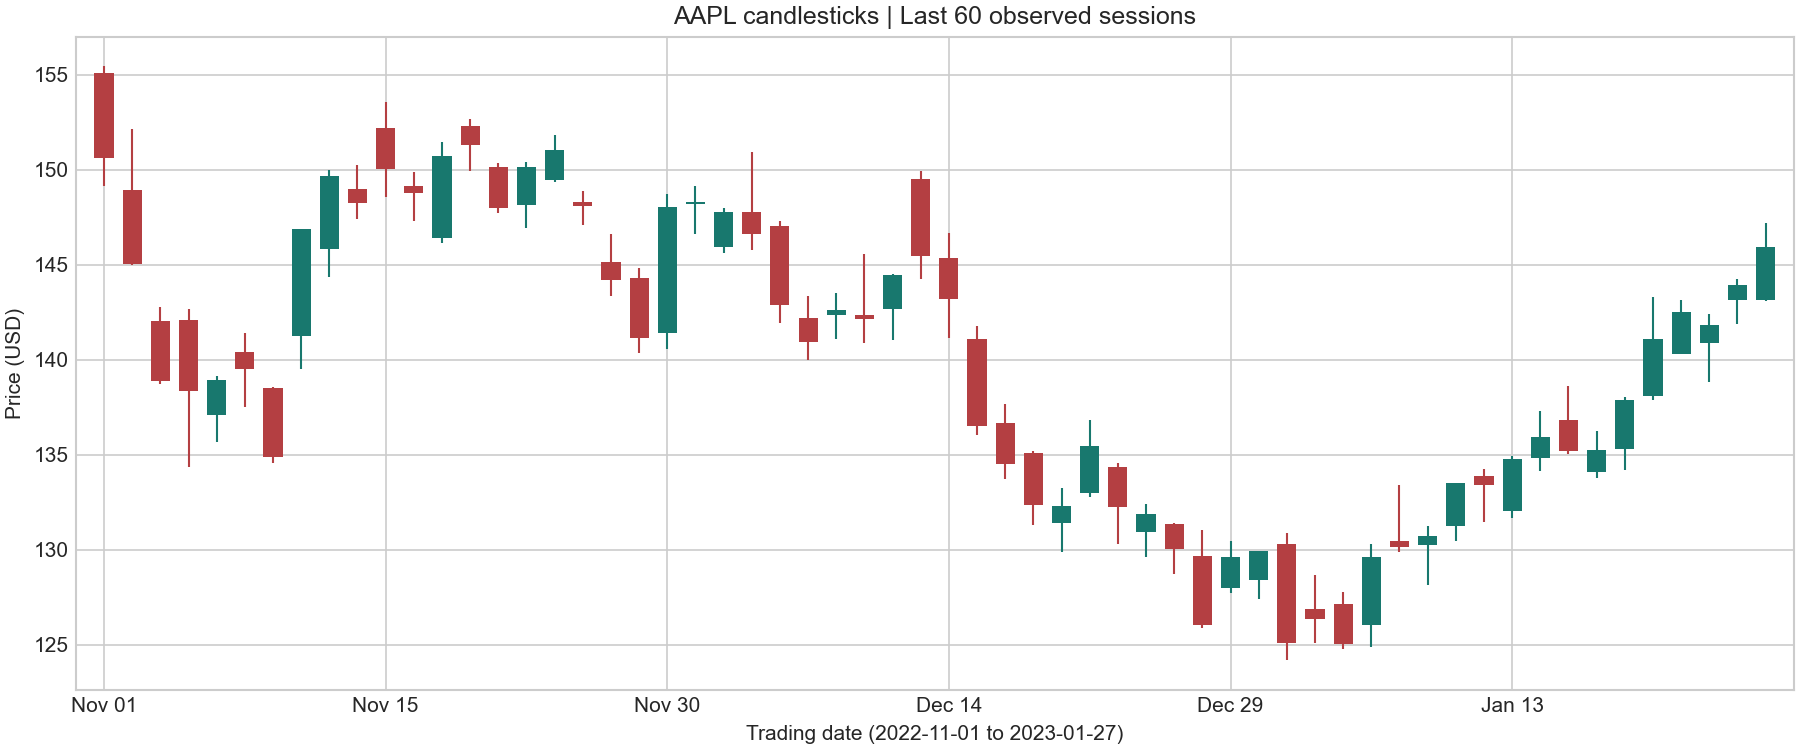

In [2]:
# Compute a trailing mean from the most recent 50 closes at each date.
stock["ma50"] = stock["close"].rolling(window=50).mean()
plt.style.use("seaborn-v0_8-whitegrid")

# Plot the full close series and traded volume on separate axes.
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
axes[0].plot(dates, stock["close"], color="#194d68", lw=1, label="Close")
axes[0].plot(dates, stock["ma50"], color="#cb6624", lw=1.1, label="50-session mean")
axes[0].set(title="AAPL closing price", ylabel="USD (log scale)", yscale="log")
axes[0].legend(loc="upper left")
axes[1].plot(dates, stock["volume"] / 1e6, color="#287b78", lw=0.7)
axes[1].set(title="Reported traded volume", ylabel="Millions of shares", xlabel="Year")
fig.savefig("price_and_volume.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

# For each candle, draw its wick, followed by the body or a flat close line.
recent = stock.tail(60)
positions = np.arange(len(recent))
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
for position, row in zip(positions, recent.itertuples()):
    color = "#18786e" if row.close >= row.open else "#b43f42"
    ax.vlines(position, row.low, row.high, color=color, lw=1)
    body_height = abs(row.close - row.open)
    if body_height:
        ax.add_patch(Rectangle((position - 0.34, min(row.open, row.close)),
                               0.68, body_height, facecolor=color))
    else:
        ax.hlines(row.close, position - 0.34, position + 0.34, color=color)
tick_positions = np.arange(0, len(recent), 10)
ax.set_xticks(tick_positions, recent.index[tick_positions].strftime("%b %d"))
ax.set(title="AAPL candlesticks | Last 60 observed sessions",
       xlabel=f"Trading date ({recent.index[0]:%Y-%m-%d} to {recent.index[-1]:%Y-%m-%d})",
       ylabel="Price (USD)", xlim=(-1, len(recent)))
fig.savefig("candlesticks.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

# 3. Summary statistics and moving average

Use the sample standard deviation. The moving average is trailing and starts once the dataset has 50 observations. It smooths short-term changes and typically lags turning points.

In [3]:
# Summarize prices and share volume in their original units.
summary = stock[columns].agg(["mean", "median", "std"]).T
print(summary.to_string(float_format=lambda number: f"{number:,.4f}"))

# Verify the pandas moving average using convolution with equal weights.
close = stock["close"].to_numpy()
weights = np.full(50, 1 / 50)
convolved = np.convolve(close, weights, mode="valid")
np.testing.assert_allclose(convolved, stock["ma50"].dropna().to_numpy())
above_average = (stock["close"] > stock["ma50"])[stock["ma50"].notna()].mean()
print(f"\nFinal close: ${close[-1]:.2f}; final 50-session average: ${convolved[-1]:.2f}")
print(f"Close above its moving average: {above_average:.1%} of eligible sessions.")


                      mean           median              std
open               16.6892           0.4888          35.4505
high               16.8800           0.4955          35.8828
low                16.5008           0.4804          35.0313
close              16.6974           0.4877          35.4739
adj_close          16.0273           0.4049          35.1549
volume    327,509,817.2606 214,597,600.0000 337,820,279.0577

Final close: $145.93; final 50-session average: $139.11
Close above its moving average: 59.7% of eligible sessions.


# 4. Test closing prices and daily return normality

The two-sided Welch test compares mean raw closes for calendar years 2021 and 2022 under an independence assumption. Serial dependence and trends in price levels limit the interpretation of its nominal p-value. Returns use adjusted closing prices to account for the adjustments made by the source. The D’Agostino–Pearson test assesses whether return skewness and kurtosis are consistent with normality. The test's reference p-value also assumes independent observations.

2021 mean close: $140.99 (n=252); 2022 mean close: $154.84 (n=251)
Welch t = -11.187; nominal p = 4.71e-26
Lag-1 price correlation in 2022: 0.965

Adjusted daily returns: n = 10,607; mean = 0.108%; SD = 2.823%
Skewness = -0.377; excess kurtosis = 18.145
Normality K² = 2721.39; nominal log10(p) = -590.9


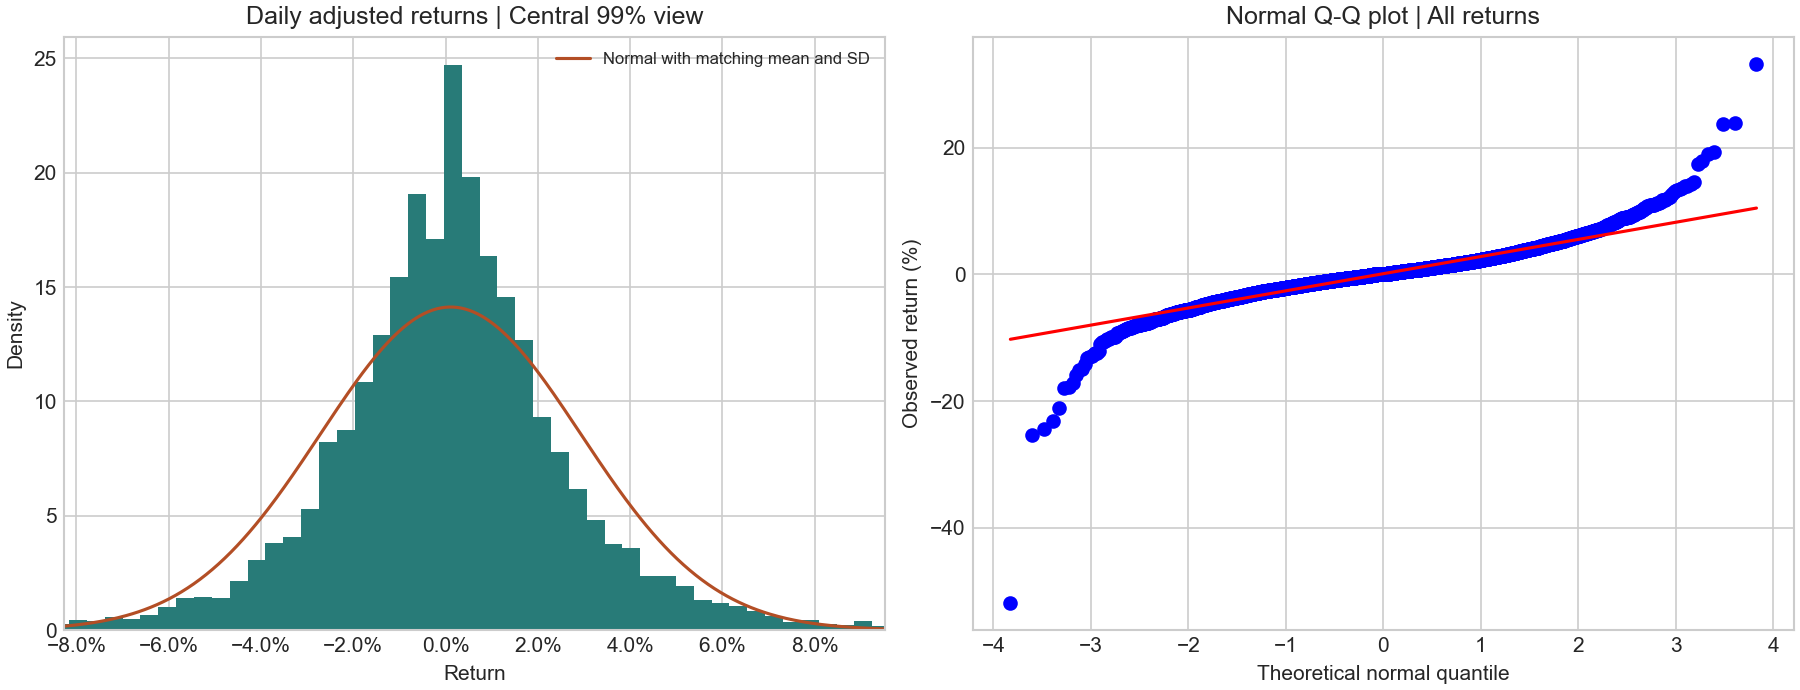

In [4]:
# Compare two full years. Welch's method allows different group variances.
year_a = stock.loc["2021", "close"].to_numpy()
year_b = stock.loc["2022", "close"].to_numpy()
welch = stats.ttest_ind(year_a, year_b, equal_var=False)
price_lag_one = np.corrcoef(year_b[:-1], year_b[1:])[0, 1]
print(f"2021 mean close: ${year_a.mean():.2f} (n={year_a.size}); "
      f"2022 mean close: ${year_b.mean():.2f} (n={year_b.size})")
print(f"Welch t = {welch.statistic:.3f}; nominal p = {welch.pvalue:.4g}")
print(f"Lag-1 price correlation in 2022: {price_lag_one:.3f}")

# Calculate simple adjusted returns and examine their shape.
returns = stock["adj_close"].pct_change(fill_method=None).dropna().to_numpy()
normality = stats.normaltest(returns)
skewness = stats.skew(returns, bias=False)
excess_kurtosis = stats.kurtosis(returns, fisher=True, bias=False)
print(f"\nAdjusted daily returns: n = {returns.size:,}; mean = {returns.mean():.3%}; "
      f"SD = {returns.std(ddof=1):.3%}")
print(f"Skewness = {skewness:.3f}; excess kurtosis = {excess_kurtosis:.3f}")
# The chi-square reference has 2 df, with survival probability exp(-K²/2).
# Report log10(p) because this p-value is too small for a floating-point number.
log10_normality_p = -normality.statistic / (2 * np.log(10))
print(f"Normality K² = {normality.statistic:.2f}; nominal log10(p) = {log10_normality_p:.1f}")

# Plot all observations in a Q-Q plot and zoom the histogram to its central range.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
bounds = np.quantile(returns, [0.005, 0.995])
axes[0].hist(returns, bins=220, density=True, color="#287b78")
grid = np.linspace(*bounds, 400)
axes[0].plot(grid, stats.norm.pdf(grid, returns.mean(), returns.std(ddof=1)),
             color="#b34e25", label="Normal with matching mean and SD")
axes[0].set(title="Daily adjusted returns | Central 99% view", xlim=bounds,
            xlabel="Return", ylabel="Density")
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=8)
stats.probplot(returns * 100, dist="norm", plot=axes[1])
axes[1].set(title="Normal Q-Q plot | All returns", xlabel="Theoretical normal quantile",
            ylabel="Observed return (%)")
fig.savefig("return_distribution.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

# 5. Bonus | Signal processing and correlations

Compare two SciPy Savitzky–Golay smoothers. Their centered windows use future observations, so their output is suitable for retrospective plots. Correlations between price levels and volume are descriptive and can shift with the time period.

   Period  Sessions  50-day price avg vs daily volume  50-day avg price vs avg volume
2000–2009      2515                             0.464                           0.663
2010–2019      2516                            -0.636                          -0.794
2020–2022       756                            -0.545                          -0.762


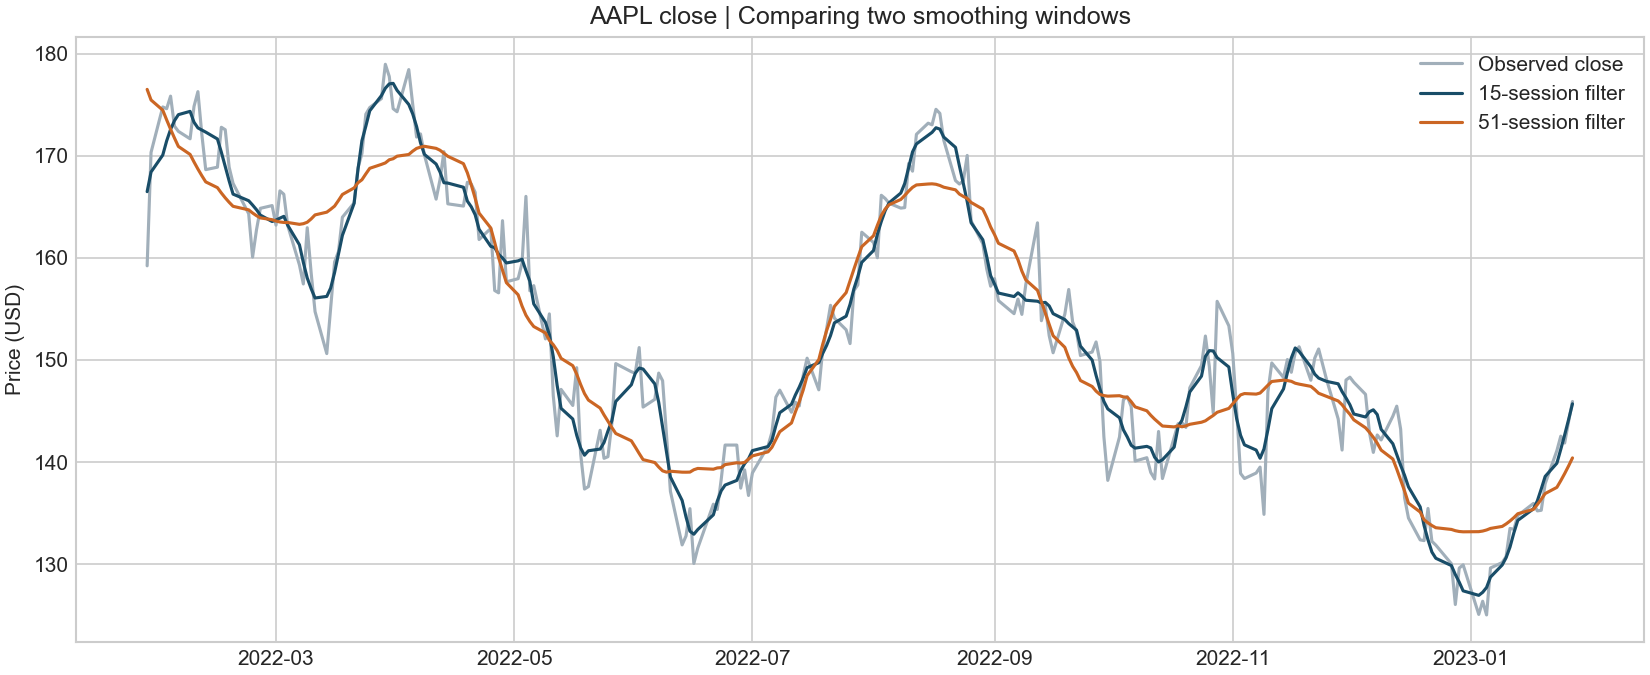

In [5]:
# Smooth one recent year with short and long odd windows and a quadratic fit.
sample = stock.tail(252)
sample_prices = sample["close"].to_numpy()
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
ax.plot(sample.index, sample_prices, color="#a1afba", label="Observed close")
for window, color in [(15, "#194d68"), (51, "#cb6624")]:
    smoothed = signal.savgol_filter(sample_prices, window_length=window, polyorder=2)
    ax.plot(sample.index, smoothed, color=color, label=f"{window}-session filter")
ax.set(title="AAPL close | Comparing two smoothing windows", ylabel="Price (USD)")
ax.legend()
fig.savefig("signal_smoothing.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

# Compare both same-day volume and trailing mean volume with the price average.
stock["volume_ma50"] = stock["volume"].rolling(50).mean()
periods = {"2000–2009": ("2000", "2009"), "2010–2019": ("2010", "2019"),
           "2020–2022": ("2020", "2022")}
correlations = []
for label, (start, end) in periods.items():
    paired = stock.loc[start:end, ["ma50", "volume", "volume_ma50"]].dropna()
    matrix = np.corrcoef(paired.to_numpy(), rowvar=False)
    correlations.append((label, len(paired), matrix[0, 1], matrix[0, 2]))
correlation_summary = pd.DataFrame(correlations, columns=[
    "Period", "Sessions", "50-day price avg vs daily volume", "50-day avg price vs avg volume"
])
print(correlation_summary.round(3).to_string(index=False))

# 6. Summary and insights

The closing-price chart describes a historical series. The return chart and Q-Q plot show how different the distribution of daily changes is from the fitted normal curve. The bonus analysis shows how the size of the smoothing window changes visible turning points.

In [6]:
normality_conclusion = ("rejects normality at the 5% level" if normality.pvalue < 0.05
                        else "does not reject normality at the 5% level")
print(f"The supplied series spans {dates[0]:%Y-%m-%d} to {dates[-1]:%Y-%m-%d}.")
print(f"The first and last closes are ${close[0]:.4f} and ${close[-1]:.2f} on the source's scale.")
print(f"2022 averaged ${year_b.mean() - year_a.mean():.2f} more per close than 2021.")
print("The daily price observations are serially dependent, so the Welch p-value is illustrative.")
print(f"The return normality test {normality_conclusion}. "
      f"Excess kurtosis of {excess_kurtosis:.1f} indicates unusually heavy tails.")
print("The 51-session filter suppresses more short-term movement than the 15-session filter.")
print("Price-average correlations with volume are positive in 2000-2009 and negative in both later periods.")


The supplied series spans 1981-01-02 to 2023-01-27.
The first and last closes are $0.1540 and $145.93 on the source's scale.
2022 averaged $13.85 more per close than 2021.
The daily price observations are serially dependent, so the Welch p-value is illustrative.
The return normality test rejects normality at the 5% level. Excess kurtosis of 18.1 indicates unusually heavy tails.
The 51-session filter suppresses more short-term movement than the 15-session filter.
Price-average correlations with volume are positive in 2000-2009 and negative in both later periods.


# 7. Reflection

**Dates and missing days.** I parsed the source explicitly as day/month/year, sorted the trading dates, and kept observation spacing as supplied. The 2023 portion ends in January. Filling weekends with a repeated close would create artificial zero returns and change the distribution.

**Price scale and corporate actions.** I used the supplied OHLC columns for price charts and adjusted closes for returns. I kept the course archive alongside the notebook so pricing conventions and coverage can be traced back to the same source.

**Statistical interpretation.** Daily closing prices have strong serial dependence and may trend. Welch’s test demonstrates the course method, with its limitations stated. A stronger inference about financial dynamics would use returns and methods that account for time dependence, such as a block bootstrap.

**Smoothing.** A trailing moving average is available at each date once its window is full. The centered Savitzky–Golay filter also uses later observations. Trying two windows shows the tradeoff between preserving local detail and suppressing noise.